# Projeto 2 — Segurança, Privacidade e Clustering em Dados de Recursos Humanos

Débora Jesus Nº2250064 / João Coelho Nº2200881

Este notebook implementa o processo completo pedido no projeto:

1. **Base de Dados original** com dados de entradas, saídas e entrevistas de saída de colaboradores.
2. **Clustering na BD original**.
3. **Anonimização / pseudonimização / codificação** da base de dados.
4. **Clustering na BD protegida**.
5. **Desanonimização interpretativa** através de tabelas de mapeamento controladas.
6. **Comparação dos clusters** entre a BD original e a BD protegida.

O objetivo é demonstrar que é possível proteger dados sensíveis e, ao mesmo tempo, manter a utilidade analítica da base de dados.


## 1. Importação das bibliotecas

In [1]:
import os
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Carregamento da Base de Dados Original

O notebook tenta carregar o ficheiro `dataset_rh_projeto2_original_10000.csv`.

Caso o ficheiro não esteja disponível no Colab, o notebook permite fazer upload manual. Se ainda assim não existir ficheiro, é gerado um dataset sintético equivalente, com **10.000 linhas e 10 colunas**.

In [2]:
def generate_synthetic_hr_dataset(n=10000, random_state=42):
    """Gera um dataset sintético de RH alinhado com os objetivos do projeto."""
    rng = np.random.default_rng(random_state)

    exit_reasons = rng.choice(
        ['Career Progression', 'Underperformance', 'Retirement'],
        size=n,
        p=[0.45, 0.35, 0.20]
    )

    employee_id = [f'EMP{i:05d}' for i in range(1, n + 1)]
    gender = rng.choice(['Male', 'Female'], size=n, p=[0.52, 0.48])
    department = rng.choice(['Sales', 'Operations', 'Finance', 'HR', 'IT', 'Marketing'], size=n,
                            p=[0.25, 0.25, 0.15, 0.10, 0.15, 0.10])

    age = np.zeros(n, dtype=int)
    tenure = np.zeros(n)
    performance = np.zeros(n)
    exit_score = np.zeros(n)

    for i, reason in enumerate(exit_reasons):
        if reason == 'Career Progression':
            age[i] = int(np.clip(rng.normal(31, 5), 22, 45))
            tenure[i] = np.round(np.clip(rng.normal(3.2, 1.4), 0.5, 8), 1)
            performance[i] = np.round(np.clip(rng.normal(3.8, 0.55), 2.0, 5.0), 1)
            exit_score[i] = np.round(np.clip(rng.normal(3.8, 0.45), 2.3, 5.0), 1)
        elif reason == 'Underperformance':
            age[i] = int(np.clip(rng.normal(39, 8), 24, 58))
            tenure[i] = np.round(np.clip(rng.normal(4.6, 2.3), 0.5, 12), 1)
            performance[i] = np.round(np.clip(rng.normal(1.8, 0.45), 1.0, 3.0), 1)
            exit_score[i] = np.round(np.clip(rng.normal(2.1, 0.55), 1.0, 3.5), 1)
        else:
            age[i] = int(np.clip(rng.normal(62, 3), 55, 68))
            tenure[i] = np.round(np.clip(rng.normal(23, 5), 12, 40), 1)
            performance[i] = np.round(np.clip(rng.normal(3.4, 0.55), 2.0, 5.0), 1)
            exit_score[i] = np.round(np.clip(rng.normal(4.1, 0.45), 2.5, 5.0), 1)

    exit_dates = pd.to_datetime(rng.choice(pd.date_range('2022-01-01', '2025-12-31', freq='D'), size=n))
    hire_dates = exit_dates - pd.to_timedelta((tenure * 365).astype(int), unit='D')

    df = pd.DataFrame({
        'Employee_ID': employee_id,
        'Age': age,
        'Gender': gender,
        'Department': department,
        'Hire_Date': hire_dates.strftime('%Y-%m-%d'),
        'Exit_Date': exit_dates.strftime('%Y-%m-%d'),
        'Tenure_Years': tenure,
        'Performance_Score': performance,
        'Exit_Reason': exit_reasons,
        'Exit_Interview_Score': exit_score
    })
    return df

DATA_PATH = 'dataset_rh_projeto2_original_10000.csv'
LEGACY_DATA_PATH = 'dataset_rh_trabalho2_original_10000.csv'

if (not os.path.exists(DATA_PATH)) and os.path.exists(LEGACY_DATA_PATH):
    DATA_PATH = LEGACY_DATA_PATH

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print('Ficheiro não encontrado. Faz upload do dataset original CSV:')
        uploaded = files.upload()
        if len(uploaded) > 0:
            DATA_PATH = list(uploaded.keys())[0]
    except Exception:
        pass

if os.path.exists(DATA_PATH):
    df_original = pd.read_csv(DATA_PATH)
else:
    print('Nenhum ficheiro carregado. A gerar dataset sintético equivalente...')
    df_original = generate_synthetic_hr_dataset(n=10000, random_state=RANDOM_STATE)
    df_original.to_csv('dataset_rh_projeto2_original_10000.csv', index=False)

df_original.head()

Ficheiro não encontrado. Faz upload do dataset original CSV:


Saving dataset_rh_trabalho2_original_10000.csv to dataset_rh_trabalho2_original_10000.csv


,Employee_ID,Age,Gender,Department,Hire_Date,Exit_Date,Tenure_Years,Performance_Score,Exit_Reason,Exit_Interview_Score
0,EMP00001,26,Female,Operations,2018-05-27,2022-02-06,3.7,3,Career Progression,3.5
1,EMP00002,28,Female,Operations,2018-09-17,2021-02-09,2.4,2,Underperformance,3.0
2,EMP00003,29,Female,IT,2021-04-23,2023-08-11,2.3,1,Underperformance,2.1
3,EMP00004,60,Female,Sales,2010-08-26,2022-10-01,12.1,4,Retirement,4.6
4,EMP00005,58,Male,Marketing,1995-12-10,2022-06-10,26.5,4,Retirement,3.8


## 3. Validação do Dataset


In [3]:
print('Dimensão do dataset:', df_original.shape)
print('Número de linhas:', df_original.shape[0])
print('Número de colunas:', df_original.shape[1])

assert 5 <= df_original.shape[1] <= 10, 'O dataset deve ter entre 5 e 10 colunas.'
assert df_original.shape[0] == 10000, 'O dataset deve ter 10.000 linhas.'

print('\nColunas:')
print(df_original.columns.tolist())

df_original.info()

Dimensão do dataset: (10000, 10)
Número de linhas: 10000
Número de colunas: 10

Colunas:
['Employee_ID', 'Age', 'Gender', 'Department', 'Hire_Date', 'Exit_Date', 'Tenure_Years', 'Performance_Score', 'Exit_Reason', 'Exit_Interview_Score']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           10000 non-null  object 
 1   Age                   10000 non-null  int64  
 2   Gender                10000 non-null  object 
 3   Department            10000 non-null  object 
 4   Hire_Date             10000 non-null  object 
 5   Exit_Date             10000 non-null  object 
 6   Tenure_Years          10000 non-null  float64
 7   Performance_Score     10000 non-null  int64  
 8   Exit_Reason           10000 non-null  object 
 9   Exit_Interview_Score  10000 non-null  float64
dtypes: float64(2), int64(2), object(6)
me

## 4. Dicionário de Dados e Classificação de Sensibilidade

Esta etapa identifica quais as variáveis úteis para análise e quais devem ser protegidas por razões de privacidade.

In [4]:
data_dictionary = pd.DataFrame({
    'Coluna': ['Employee_ID', 'Age', 'Gender', 'Department', 'Hire_Date', 'Exit_Date',
               'Tenure_Years', 'Performance_Score', 'Exit_Reason', 'Exit_Interview_Score'],
    'Descrição': [
        'Identificador interno do colaborador',
        'Idade do colaborador',
        'Género do colaborador',
        'Departamento onde trabalhava',
        'Data de entrada na organização',
        'Data de saída da organização',
        'Antiguidade em anos',
        'Avaliação de desempenho',
        'Motivo de saída',
        'Score da entrevista de saída'
    ],
    'Sensibilidade': [
        'Alta', 'Média/Alta', 'Média/Alta', 'Média', 'Média', 'Média',
        'Média', 'Alta', 'Alta', 'Alta'
    ],
    'Tratamento na BD protegida': [
        'Pseudonimização por hash com salt',
        'Generalização em grupo etário',
        'Codificação categórica',
        'Codificação categórica',
        'Removida da BD protegida direta',
        'Removida da BD protegida direta',
        'Mantida por ser necessária à análise',
        'Mantida, mas considerada métrica sensível',
        'Codificação categórica',
        'Mantida, mas considerada métrica sensível'
    ]
})

data_dictionary

,Coluna,Descrição,Sensibilidade,Tratamento na BD protegida
0,Employee_ID,Identificador interno do colaborador,Alta,Pseudonimização por hash com salt
1,Age,Idade do colaborador,Média/Alta,Generalização em grupo etário
2,Gender,Género do colaborador,Média/Alta,Codificação categórica
3,Department,Departamento onde trabalhava,Média,Codificação categórica
4,Hire_Date,Data de entrada na organização,Média,Removida da BD protegida direta
5,Exit_Date,Data de saída da organização,Média,Removida da BD protegida direta
6,Tenure_Years,Antiguidade em anos,Média,Mantida por ser necessária à análise
7,Performance_Score,Avaliação de desempenho,Alta,"Mantida, mas considerada métrica sensível"
8,Exit_Reason,Motivo de saída,Alta,Codificação categórica
9,Exit_Interview_Score,Score da entrevista de saída,Alta,"Mantida, mas considerada métrica sensível"


## 5. Análise Exploratória Inicial

Antes do clustering, é importante confirmar se existem padrões coerentes nos dados. O dataset foi construído para representar três perfis esperados:

- **Career Progression**: saída por progressão de carreira ou mudança de área.
- **Underperformance**: saída associada a baixo desempenho.
- **Retirement**: saída por reforma.

In [5]:
print('Valores em falta por coluna:')
display(df_original.isna().sum())

print('\nDistribuição dos motivos de saída:')
display(df_original['Exit_Reason'].value_counts().to_frame('N'))

print('\nResumo por motivo de saída:')
summary_by_reason = df_original.groupby('Exit_Reason')[['Age', 'Tenure_Years', 'Performance_Score', 'Exit_Interview_Score']].mean().round(2)
display(summary_by_reason)

Valores em falta por coluna:


,0
Employee_ID,0
Age,0
Gender,0
Department,0
Hire_Date,0
Exit_Date,0
Tenure_Years,0
Performance_Score,0
Exit_Reason,0
Exit_Interview_Score,0



Distribuição dos motivos de saída:


,N
Exit_Reason,
Career Progression,4453
Underperformance,3496
Retirement,2051



Resumo por motivo de saída:


,Age,Tenure_Years,Performance_Score,Exit_Interview_Score
Exit_Reason,,,,
Career Progression,31.02,3.23,3.98,3.78
Retirement,62.03,24.03,3.57,4.07
Underperformance,39.18,2.60,1.72,2.12


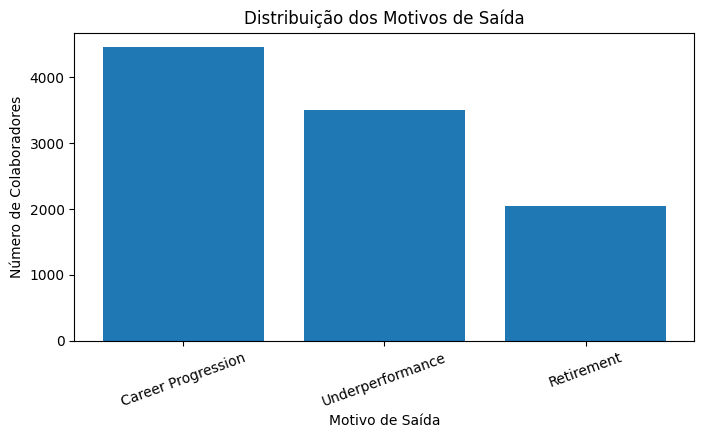

In [6]:
counts = df_original['Exit_Reason'].value_counts()
plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values)
plt.title('Distribuição dos Motivos de Saída')
plt.xlabel('Motivo de Saída')
plt.ylabel('Número de Colaboradores')
plt.xticks(rotation=20)
plt.show()

## 6. Clustering na Base de Dados Original

Para o clustering, não se usa o `Employee_ID`, porque é apenas um identificador. Também não são usadas diretamente as datas, porque a variável `Tenure_Years` já resume a informação temporal relevante.

Variáveis usadas:

- `Age`
- `Tenure_Years`
- `Performance_Score`
- `Exit_Interview_Score`

Foi aplicado K-Means com 3 clusters, uma vez que o projeto parte de três perfis esperados e essa escolha foi validada através do método do cotovelo e do coeficiente silhouette.

In [7]:
features_original = ['Age', 'Tenure_Years', 'Performance_Score', 'Exit_Interview_Score']
X_original = df_original[features_original].copy()

scaler_original = StandardScaler()
X_original_scaled = scaler_original.fit_transform(X_original)

k_values = range(2, 6)
inertias = []
silhouettes = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=1, algorithm='lloyd', max_iter=100)
    labels = model.fit_predict(X_original_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_original_scaled, labels, sample_size=200, random_state=RANDOM_STATE))

k_eval = pd.DataFrame({'k': list(k_values), 'Inertia': inertias, 'Silhouette': silhouettes})
k_eval

,k,Inertia,Silhouette
0,2,25368.568221,0.365813
1,3,9850.888285,0.539362
2,4,9304.200638,0.449836
3,5,8028.883509,0.323905


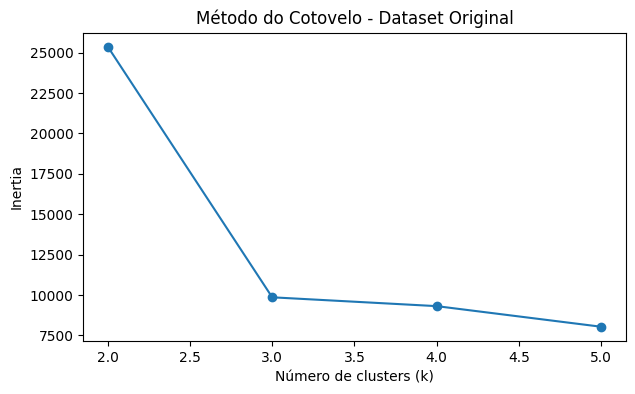

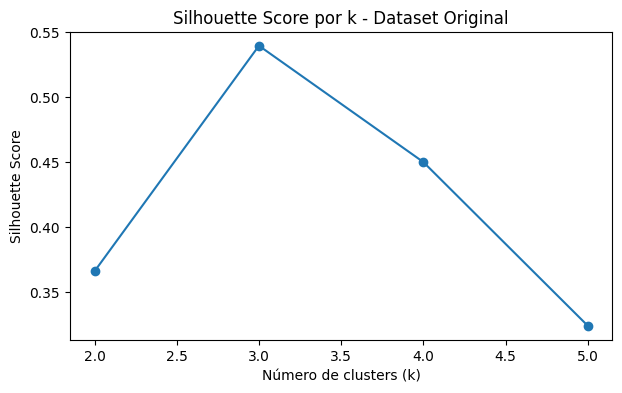

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(k_eval['k'], k_eval['Inertia'], marker='o')
plt.title('Método do Cotovelo - Dataset Original')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inertia')
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(k_eval['k'], k_eval['Silhouette'], marker='o')
plt.title('Silhouette Score por k - Dataset Original')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()

In [9]:
kmeans_original = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=1, algorithm='lloyd', max_iter=100)
df_original['Cluster_Original'] = kmeans_original.fit_predict(X_original_scaled)

print('Silhouette Score - clustering original:', round(silhouette_score(X_original_scaled, df_original['Cluster_Original'], sample_size=200, random_state=RANDOM_STATE), 4))
pd.crosstab(df_original['Cluster_Original'], df_original['Exit_Reason'])

Silhouette Score - clustering original: 0.5394


Exit_Reason,Career Progression,Retirement,Underperformance
Cluster_Original,,,
0,102,0,3444
1,4351,0,52
2,0,2051,0


## 7. Interpretação dos Clusters Originais

A interpretação dos clusters é feita através das médias das variáveis numéricas e do motivo de saída dominante em cada cluster.

In [10]:
def build_cluster_profile(df, cluster_col, reason_col='Exit_Reason'):
    base = df.groupby(cluster_col).agg(
        N=('Employee_ID', 'count'),
        Age_Mean=('Age', 'mean'),
        Tenure_Mean=('Tenure_Years', 'mean'),
        Performance_Mean=('Performance_Score', 'mean'),
        Exit_Interview_Mean=('Exit_Interview_Score', 'mean')
    ).round(2)

    dominant_reason = df.groupby(cluster_col)[reason_col].agg(lambda x: x.value_counts().index[0])
    dominant_share = df.groupby(cluster_col)[reason_col].agg(lambda x: x.value_counts(normalize=True).iloc[0]).round(3)

    profile = base.copy()
    profile['Dominant_Exit_Reason'] = dominant_reason
    profile['Dominant_Reason_Share'] = dominant_share
    interpretation_map = {
        'Career Progression': 'Saída por progressão de carreira / mudança de área',
        'Underperformance': 'Saída associada a underperformance',
        'Retirement': 'Saída por reforma'
    }
    profile['Cluster_Interpretation'] = profile['Dominant_Exit_Reason'].map(interpretation_map)
    return profile.reset_index()

cluster_profile_original = build_cluster_profile(df_original, 'Cluster_Original')
cluster_profile_original

,Cluster_Original,N,Age_Mean,Tenure_Mean,Performance_Mean,Exit_Interview_Mean,Dominant_Exit_Reason,Dominant_Reason_Share,Cluster_Interpretation
0,0,3546,39.05,2.62,1.73,2.12,Underperformance,0.971,Saída associada a underperformance
1,1,4403,31.03,3.22,3.99,3.80,Career Progression,0.988,Saída por progressão de carreira / mudança de ...
2,2,2051,62.03,24.03,3.57,4.07,Retirement,1.000,Saída por reforma


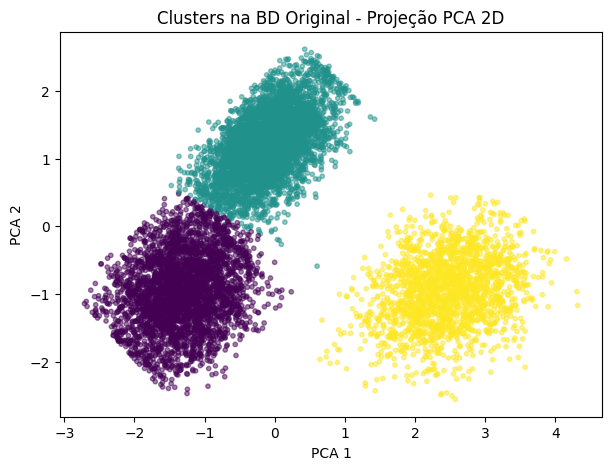

In [11]:
pca_original = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_original = pca_original.fit_transform(X_original_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca_original[:, 0], X_pca_original[:, 1], c=df_original['Cluster_Original'], alpha=0.5, s=10)
plt.title('Clusters na BD Original - Projeção PCA 2D')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()

## 8. Criação da Base de Dados Protegida

Nesta fase são aplicadas técnicas de proteção dos dados:

1. **Pseudonimização do Employee_ID** através de hash com salt.
2. **Generalização da idade** em grupos etários.
3. **Codificação de categorias** como género, departamento e motivo de saída.
4. **Remoção das datas diretas** de entrada e saída da BD protegida.
5. **Criação de tabelas de mapeamento**, que devem ser armazenadas separadamente e com acesso restrito.

A tabela `identity_map` é sensível, pois permite associar o identificador original ao identificador protegido.

In [12]:
def salted_hash(value, salt='PROJETO2_SEG_PRIV_2026'):
    return hashlib.sha256(f'{salt}_{value}'.encode('utf-8')).hexdigest()[:12].upper()

protected = df_original.copy()
protected['Employee_Key'] = protected['Employee_ID'].apply(salted_hash)

age_bins = [17, 24, 34, 44, 54, 100]
age_labels = ['A1_<25', 'A2_25_34', 'A3_35_44', 'A4_45_54', 'A5_55_plus']
protected['Age_Group'] = pd.cut(protected['Age'], bins=age_bins, labels=age_labels, include_lowest=True)

age_group_ordinal_map = {
    'A1_<25': 1,
    'A2_25_34': 2,
    'A3_35_44': 3,
    'A4_45_54': 4,
    'A5_55_plus': 5
}
protected['Age_Group_Ordinal'] = protected['Age_Group'].astype(str).map(age_group_ordinal_map)

encoding_maps = {}
for col, prefix in [('Gender', 'G'), ('Department', 'D'), ('Exit_Reason', 'R')]:
    unique_values = sorted(protected[col].dropna().unique())
    mapping = {value: f'{prefix}{i+1}' for i, value in enumerate(unique_values)}
    encoding_maps[col] = mapping
    protected[f'{col}_Code'] = protected[col].map(mapping)

identity_map = protected[['Employee_ID', 'Employee_Key']].copy()

mapping_tables = []
for col, mapping in encoding_maps.items():
    temp = pd.DataFrame({
        'Variable': col,
        'Original_Value': list(mapping.keys()),
        'Protected_Code': list(mapping.values())
    })
    mapping_tables.append(temp)

age_map = pd.DataFrame({
    'Variable': 'Age_Group',
    'Original_Value': ['<25', '25-34', '35-44', '45-54', '55+'],
    'Protected_Code': ['A1_<25', 'A2_25_34', 'A3_35_44', 'A4_45_54', 'A5_55_plus']
})
code_mapping = pd.concat(mapping_tables + [age_map], ignore_index=True)

protected_final = protected[[
    'Employee_Key',
    'Age_Group',
    'Age_Group_Ordinal',
    'Gender_Code',
    'Department_Code',
    'Tenure_Years',
    'Performance_Score',
    'Exit_Reason_Code',
    'Exit_Interview_Score'
]].copy()

protected_final.head()

,Employee_Key,Age_Group,Age_Group_Ordinal,Gender_Code,Department_Code,Tenure_Years,Performance_Score,Exit_Reason_Code,Exit_Interview_Score
0,A6146841616B,A2_25_34,2,G1,D6,3.7,3,R1,3.5
1,D97B8156A3A9,A2_25_34,2,G1,D6,2.4,2,R3,3.0
2,8D86E95DD0A6,A2_25_34,2,G1,D3,2.3,1,R3,2.1
3,8C78AFB617B9,A5_55_plus,5,G1,D7,12.1,4,R2,4.6
4,5359F482A2DB,A5_55_plus,5,G2,D5,26.5,4,R2,3.8


In [13]:
print('Dimensão da BD protegida:', protected_final.shape)
print('Colunas da BD protegida:')
print(protected_final.columns.tolist())

print('\nExemplo da tabela de mapeamento de códigos:')
display(code_mapping)

print('\nExemplo da tabela sensível de identidade:')
display(identity_map.head())

Dimensão da BD protegida: (10000, 9)
Colunas da BD protegida:
['Employee_Key', 'Age_Group', 'Age_Group_Ordinal', 'Gender_Code', 'Department_Code', 'Tenure_Years', 'Performance_Score', 'Exit_Reason_Code', 'Exit_Interview_Score']

Exemplo da tabela de mapeamento de códigos:


,Variable,Original_Value,Protected_Code
0,Gender,Female,G1
1,Gender,Male,G2
2,Gender,Other/Not disclosed,G3
3,Department,Finance,D1
4,Department,Human Resources,D2
5,Department,IT,D3
6,Department,Logistics,D4
7,Department,Marketing,D5
8,Department,Operations,D6
9,Department,Sales,D7



Exemplo da tabela sensível de identidade:


,Employee_ID,Employee_Key
0,EMP00001,A6146841616B
1,EMP00002,D97B8156A3A9
2,EMP00003,8D86E95DD0A6
3,EMP00004,8C78AFB617B9
4,EMP00005,5359F482A2DB


## 9. Clustering na Base de Dados Protegida

Na BD protegida, a idade exata já não é usada. Em vez disso, usa-se `Age_Group_Ordinal`, que representa apenas o grupo etário codificado.

Variáveis usadas:

- `Age_Group_Ordinal`
- `Tenure_Years`
- `Performance_Score`
- `Exit_Interview_Score`

Isto reduz a exposição da idade exata, mas mantém informação suficiente para distinguir, por exemplo, o cluster de reforma.

In [14]:
features_protected = ['Age_Group_Ordinal', 'Tenure_Years', 'Performance_Score', 'Exit_Interview_Score']
X_protected = protected_final[features_protected].copy()

scaler_protected = StandardScaler()
X_protected_scaled = scaler_protected.fit_transform(X_protected)

kmeans_protected = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=1, algorithm='lloyd', max_iter=100)
protected_final['Cluster_Protected_Raw'] = kmeans_protected.fit_predict(X_protected_scaled)

print('Silhouette Score - clustering protegido:', round(silhouette_score(X_protected_scaled, protected_final['Cluster_Protected_Raw'], sample_size=200, random_state=RANDOM_STATE), 4))
protected_final.head()

Silhouette Score - clustering protegido: 0.5326


,Employee_Key,Age_Group,Age_Group_Ordinal,Gender_Code,Department_Code,Tenure_Years,Performance_Score,Exit_Reason_Code,Exit_Interview_Score,Cluster_Protected_Raw
0,A6146841616B,A2_25_34,2,G1,D6,3.7,3,R1,3.5,2
1,D97B8156A3A9,A2_25_34,2,G1,D6,2.4,2,R3,3.0,0
2,8D86E95DD0A6,A2_25_34,2,G1,D3,2.3,1,R3,2.1,0
3,8C78AFB617B9,A5_55_plus,5,G1,D7,12.1,4,R2,4.6,1
4,5359F482A2DB,A5_55_plus,5,G2,D5,26.5,4,R2,3.8,1


## 10. Desanonimização Interpretativa dos Resultados

A desanonimização aqui não significa expor novamente todos os dados pessoais. Significa usar as tabelas de mapeamento para interpretar os códigos dos clusters.

Para comparar corretamente o clustering original e o clustering protegido, os rótulos dos clusters são alinhados, porque o K-Means pode atribuir números diferentes a grupos equivalentes.

In [15]:
def align_cluster_labels(reference_labels, target_labels):
    """Alinha os números dos clusters do target aos clusters de referência usando Hungarian Algorithm."""
    ref = np.array(reference_labels)
    tgt = np.array(target_labels)
    labels_ref = np.unique(ref)
    labels_tgt = np.unique(tgt)

    matrix = np.zeros((len(labels_ref), len(labels_tgt)), dtype=int)
    for i, r in enumerate(labels_ref):
        for j, t in enumerate(labels_tgt):
            matrix[i, j] = np.sum((ref == r) & (tgt == t))

    row_ind, col_ind = linear_sum_assignment(-matrix)
    mapping = {labels_tgt[col]: labels_ref[row] for row, col in zip(row_ind, col_ind)}
    aligned = np.array([mapping[x] for x in tgt])
    return aligned, mapping

protected_final['Cluster_Protected'], cluster_alignment_map = align_cluster_labels(
    df_original['Cluster_Original'],
    protected_final['Cluster_Protected_Raw']
)

print('Mapeamento de alinhamento dos clusters protegidos para os clusters originais:')
print(cluster_alignment_map)

comparison_matrix = pd.crosstab(
    df_original['Cluster_Original'],
    protected_final['Cluster_Protected'],
    rownames=['Cluster Original'],
    colnames=['Cluster Protegido Alinhado']
)
comparison_matrix

Mapeamento de alinhamento dos clusters protegidos para os clusters originais:
{np.int32(0): np.int32(0), np.int32(2): np.int32(1), np.int32(1): np.int32(2)}


Cluster Protegido Alinhado,0,1,2
Cluster Original,,,
0,3534,12,0
1,12,4390,1
2,1,0,2050


In [16]:
ari_original_vs_protected = adjusted_rand_score(df_original['Cluster_Original'], protected_final['Cluster_Protected'])
ari_original_vs_reason = adjusted_rand_score(df_original['Exit_Reason'], df_original['Cluster_Original'])
ari_protected_vs_reason = adjusted_rand_score(df_original['Exit_Reason'], protected_final['Cluster_Protected'])

metrics_comparison = pd.DataFrame({
    'Comparação': [
        'Clusters Original vs Clusters Protegido',
        'Exit_Reason vs Clusters Original',
        'Exit_Reason vs Clusters Protegido'
    ],
    'Adjusted Rand Index': [
        ari_original_vs_protected,
        ari_original_vs_reason,
        ari_protected_vs_reason
    ]
})
metrics_comparison['Adjusted Rand Index'] = metrics_comparison['Adjusted Rand Index'].round(4)
metrics_comparison

,Comparação,Adjusted Rand Index
0,Clusters Original vs Clusters Protegido,0.9912
1,Exit_Reason vs Clusters Original,0.9480
2,Exit_Reason vs Clusters Protegido,0.9492


### Interpretação do ARI

O **Adjusted Rand Index (ARI)** mede a semelhança entre duas segmentações:

- Valor próximo de **1**: os agrupamentos são praticamente iguais.
- Valor próximo de **0**: a semelhança é semelhante ao acaso.
- Valor negativo: pior que uma atribuição aleatória.

Neste projeto, o valor mais importante é o ARI entre os clusters da BD original e da BD protegida. Um valor elevado mostra que a proteção dos dados preservou a utilidade analítica.

## 11. Perfil Final dos Clusters com Interpretação

Esta tabela é uma das mais importantes do projeto, porque transforma o resultado técnico do clustering numa análise interpretável.

In [17]:
analysis_df = df_original.copy()
analysis_df['Cluster_Protected'] = protected_final['Cluster_Protected']
analysis_df['Age_Group'] = protected_final['Age_Group']

cluster_profile_final = build_cluster_profile(analysis_df, 'Cluster_Protected')
cluster_profile_final

,Cluster_Protected,N,Age_Mean,Tenure_Mean,Performance_Mean,Exit_Interview_Mean,Dominant_Exit_Reason,Dominant_Reason_Share,Cluster_Interpretation
0,0,3547,39.07,2.62,1.73,2.12,Underperformance,0.972,Saída associada a underperformance
1,1,4402,31.01,3.22,3.99,3.80,Career Progression,0.989,Saída por progressão de carreira / mudança de ...
2,2,2051,62.02,24.02,3.57,4.07,Retirement,1.000,Saída por reforma


In [18]:
print('Distribuição dos motivos de saída por cluster protegido:')
display(pd.crosstab(analysis_df['Cluster_Protected'], analysis_df['Exit_Reason'], normalize='index').round(3))

print('\nResumo por cluster protegido:')
display(analysis_df.groupby('Cluster_Protected')[['Age', 'Tenure_Years', 'Performance_Score', 'Exit_Interview_Score']].mean().round(2))

Distribuição dos motivos de saída por cluster protegido:


Exit_Reason,Career Progression,Retirement,Underperformance
Cluster_Protected,,,
0,0.028,0.0,0.972
1,0.989,0.0,0.011
2,0.000,1.0,0.000



Resumo por cluster protegido:


,Age,Tenure_Years,Performance_Score,Exit_Interview_Score
Cluster_Protected,,,,
0,39.07,2.62,1.73,2.12
1,31.01,3.22,3.99,3.80
2,62.02,24.02,3.57,4.07


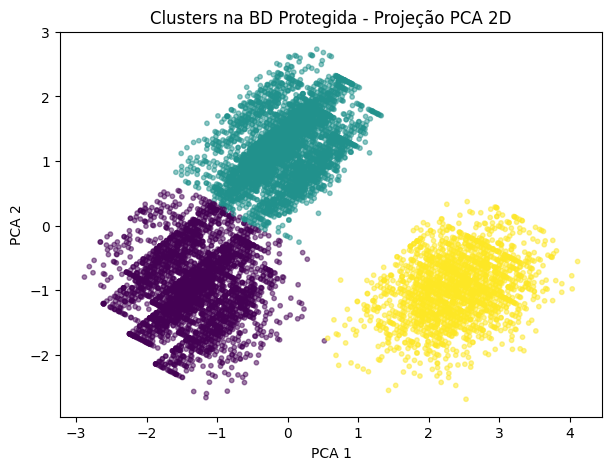

In [19]:
pca_protected = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_protected = pca_protected.fit_transform(X_protected_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca_protected[:, 0], X_pca_protected[:, 1], c=protected_final['Cluster_Protected'], alpha=0.5, s=10)
plt.title('Clusters na BD Protegida - Projeção PCA 2D')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()

## 12. Discussão de Segurança e Privacidade

A BD original contém dados pessoais e sensíveis no contexto organizacional, como identificador do colaborador, idade, género, avaliação de desempenho, motivo de saída e score da entrevista de saída.

As técnicas aplicadas foram:

- **Pseudonimização** do identificador do colaborador com hash e salt.
- **Generalização** da idade para grupos etários.
- **Codificação** de variáveis categóricas sensíveis.
- **Separação da tabela de identidade** (`identity_map`) da BD analítica.
- **Desanonimização controlada** apenas para interpretação dos resultados agregados.

### Risco principal

A tabela `identity_map` é o principal risco de privacidade, porque permite ligar o identificador real ao identificador protegido. Por isso, deve ser guardada separadamente, encriptada e acessível apenas a utilizadores autorizados, como administradores ou equipa de RH com permissões específicas.

### Preservação da utilidade analítica

Apesar da proteção dos dados, os clusters obtidos na BD protegida mantêm uma estrutura muito semelhante aos clusters obtidos na BD original. Isto mostra que a anonimização/codificação preservou a informação necessária para análise, reduzindo simultaneamente a exposição de dados pessoais.

## 13. Conclusão Final

O projeto demonstra que é possível aplicar técnicas de proteção de dados num dataset de Recursos Humanos sem perder a capacidade de identificar perfis relevantes de colaboradores.

Foram identificados três perfis principais:

1. **Progressão de carreira / mudança de área** — colaboradores geralmente mais jovens, com menor antiguidade e avaliação normal/boa.
2. **Underperformance** — colaboradores com menor avaliação de desempenho e entrevistas de saída mais negativas.
3. **Reforma** — colaboradores mais velhos e com maior antiguidade.

A comparação entre o clustering na BD original e na BD protegida apresentou um ARI elevado, demonstrando que os resultados se mantiveram consistentes após a proteção dos dados.

Assim, o notebook cumpre o objetivo central do projeto: **proteger dados sensíveis e preservar a utilidade analítica para clustering**.

## 14. Exportação dos Resultados

São exportados ficheiros para uso em relatório ou Power BI:

- `dataset_original_com_clusters.csv`
- `dataset_protegido_com_clusters.csv`
- `identity_map_restricted.csv`
- `code_mapping.csv`
- `cluster_profile_final.csv`
- `comparison_metrics.csv`
- `projeto2_resultados_finais.xlsx`

In [20]:
original_export = df_original.copy()
original_export['Cluster_Profile'] = original_export['Cluster_Original'].map(
    cluster_profile_original.set_index('Cluster_Original')['Cluster_Interpretation'].to_dict()
)

protected_export = protected_final.copy()
protected_export['Cluster_Profile'] = protected_export['Cluster_Protected'].map(
    cluster_profile_final.set_index('Cluster_Protected')['Cluster_Interpretation'].to_dict()
)

# Exportação principal em CSV, formato simples e recomendado para Power BI.
original_export.to_csv('dataset_original_com_clusters.csv', index=False)
protected_export.to_csv('dataset_protegido_com_clusters.csv', index=False)
#identity_map.to_csv('identity_map_restricted.csv', index=False)
#code_mapping.to_csv('code_mapping.csv', index=False)
#cluster_profile_final.to_csv('cluster_profile_final.csv', index=False)
#metrics_comparison.to_csv('comparison_metrics.csv', index=False)

# Exportação Excel opcional. Mantém False para o notebook correr mais rápido no Colab.
EXPORT_EXCEL = False

if EXPORT_EXCEL:
    with pd.ExcelWriter('projeto2_resultados_finais.xlsx', engine='openpyxl') as writer:
        original_export.to_excel(writer, sheet_name='Original_with_Clusters', index=False)
        protected_export.to_excel(writer, sheet_name='Protected_with_Clusters', index=False)
        cluster_profile_original.to_excel(writer, sheet_name='Original_Cluster_Profile', index=False)
        cluster_profile_final.to_excel(writer, sheet_name='Protected_Cluster_Profile', index=False)
        metrics_comparison.to_excel(writer, sheet_name='Comparison_Metrics', index=False)
        comparison_matrix.to_excel(writer, sheet_name='Cluster_Comparison')
        code_mapping.to_excel(writer, sheet_name='Code_Mapping', index=False)
        identity_map.to_excel(writer, sheet_name='Identity_Map_RESTRICTED', index=False)
        data_dictionary.to_excel(writer, sheet_name='Data_Dictionary', index=False)

print('Ficheiros exportados com sucesso.')
print('- dataset_original_com_clusters.csv')
print('- dataset_protegido_com_clusters.csv')
print('- identity_map_restricted.csv')
print('- code_mapping.csv')
print('- cluster_profile_final.csv')
print('- comparison_metrics.csv')
if EXPORT_EXCEL:
    print('- projeto2_resultados_finais.xlsx')

Ficheiros exportados com sucesso.
- dataset_original_com_clusters.csv
- dataset_protegido_com_clusters.csv
- identity_map_restricted.csv
- code_mapping.csv
- cluster_profile_final.csv
- comparison_metrics.csv
